In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import warnings
warnings.filterwarnings('ignore')

from cdrmip_extremes import utils, stats, io_disk, plotting as pl
from cdrmip_extremes.configs import COLOUR_DICT as colour_dict, SSP_MODELS, PROC_DIR, FIG_DIR

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [3]:
gsat = utils.reduce_member_tree(
    io_disk.load_tree(PROC_DIR, 'gsat', 'ScenarioMIP', model_order=SSP_MODELS, expt='ssp534-over'),
    drop_coords=['gwl']
)
gsat_rolling = utils.reduce_member_tree(
    io_disk.load_tree(PROC_DIR, 'gsat_rolling', 'ScenarioMIP', model_order=SSP_MODELS, expt='ssp534-over'),
    drop_coords=['gwl']
)
sat_difference = io_disk.load_tree(PROC_DIR, 'tas_matching_gwl_differences', 'ScenarioMIP', model_order=SSP_MODELS, expt='ssp534-over')
gwl_matching_years = utils.reduce_member_tree(
    io_disk.load_tree(PROC_DIR, 'gwl_matching_years', 'ScenarioMIP', as_dataarray=True,model_order=SSP_MODELS, expt='ssp534-over'),
    drop_coords=['gwl']
)

In [4]:
member_reduced = utils.reduce_member_tree(sat_difference, drop_coords=["gwl"])
sat_diff_agreement = stats.calc_agreement(member_reduced, expt="ssp534-over", drop_coords=["gwl"])
sat_diff = utils.reduce_models(member_reduced, drop_coords=["gwl"])

In [5]:
CO2 = utils.build_co2_path()
co2 = CO2.assign_coords(year=CO2.year - 100)

## Plot

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/Figure_S1.jpg


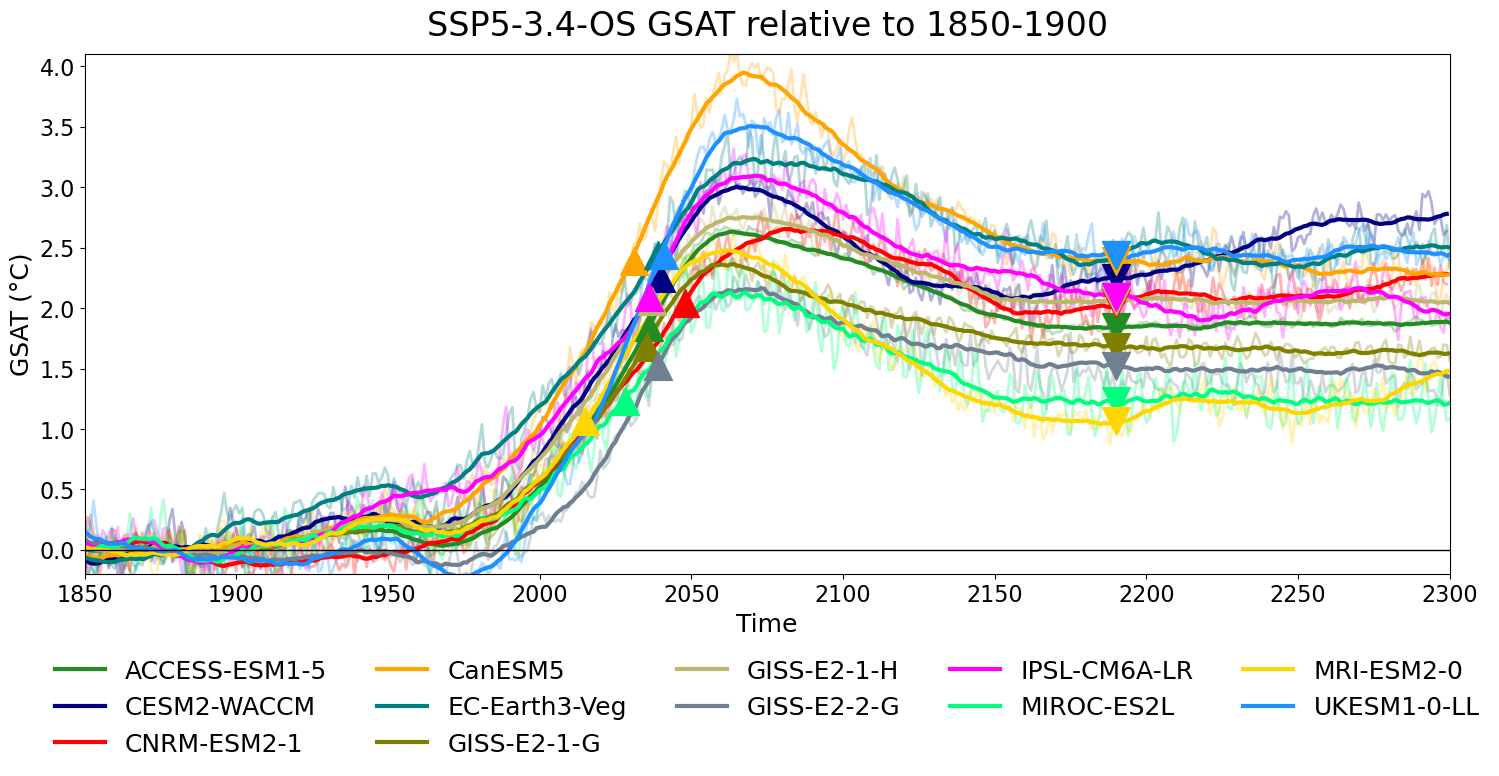

In [9]:
fig = pl.plot_gsat_timeseries(
    gsat_rolling,
    colour_dict,
    raw_tree=gsat,
    gwl_matching_years = gwl_matching_years,
    title = 'SSP5-3.4-OS GSAT relative to 1850-1900',
    fig_dir = FIG_DIR, folder = 'supplementary', file_name = 'Figure_S1.jpg'
)

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/Figure_S2.jpg


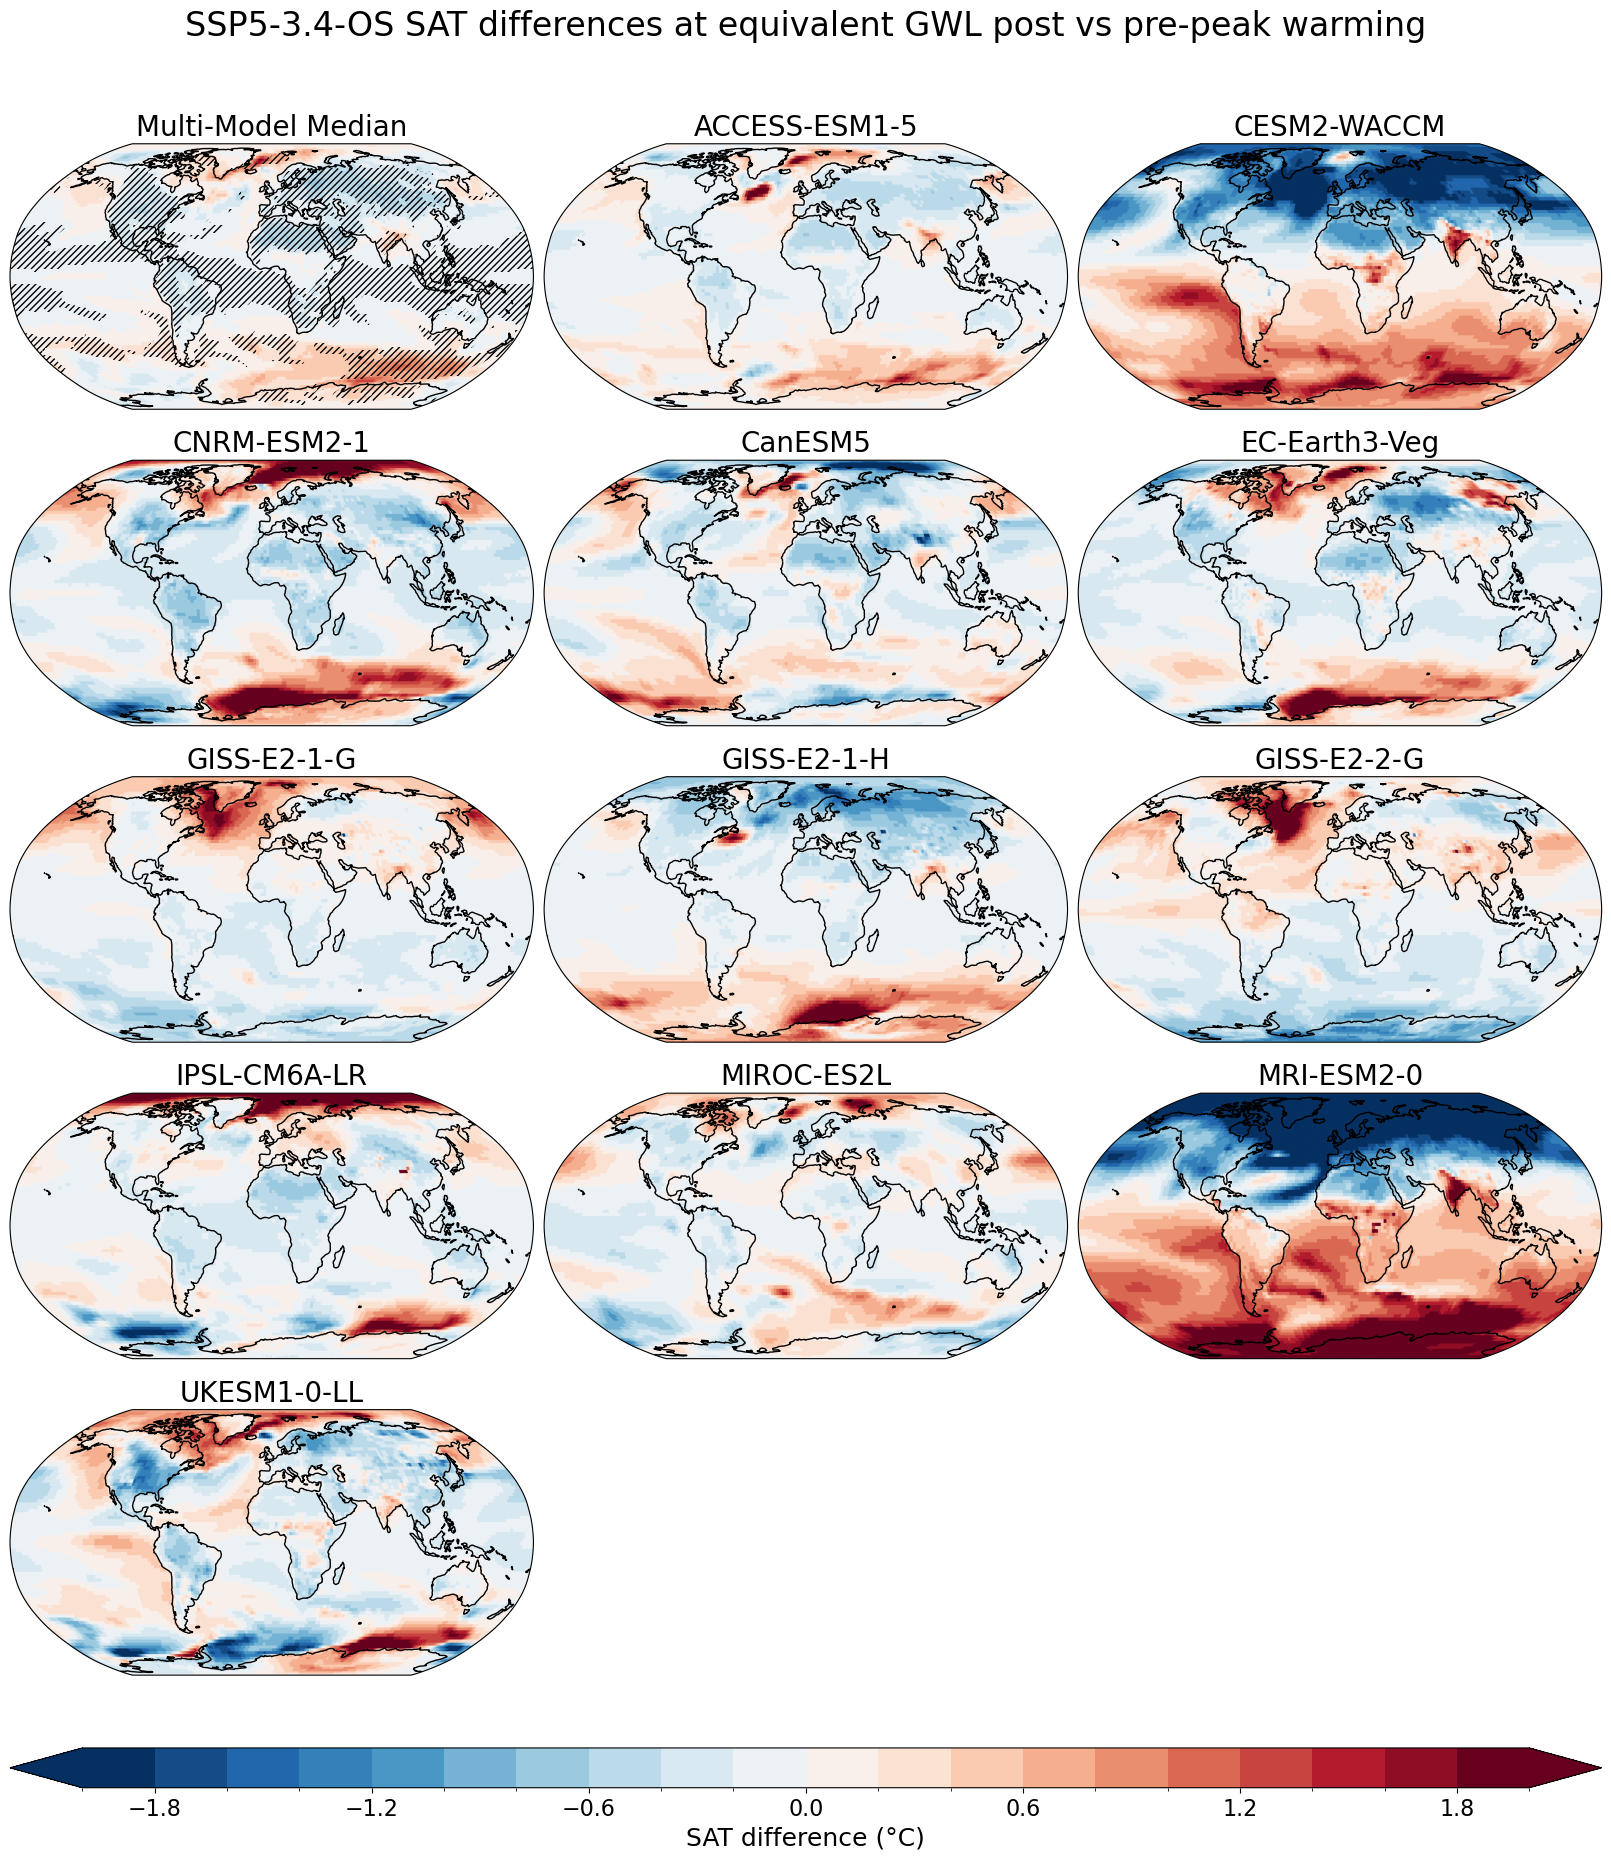

In [11]:
fig, axes = pl.plot_gwl_diff(
    sat_diff,
    'ssp534-over',
    levels=np.linspace(-2,2,21),
    agreement = sat_diff_agreement,
    suptitle = "SSP5-3.4-OS SAT differences at equivalent GWL post vs pre-peak warming",
    period='equivalent',
    figsize=(16,17.5),
    fig_dir = FIG_DIR, folder = 'supplementary', file_name = 'Figure_S2.jpg'
)